# Notebook 1: Tempo Locking (Experiment 01)

## Learning Objectives

1. Demonstrate that the HEU **phase-locks** to a rhythmic pulse train
2. Show refractory period prevents double-firing
3. Measure **accent sensitivity** (compression behavior)
4. Test robustness to **timing jitter** (humanization)
5. Understand Phase Locking Value (PLV) as a metric

---

## Hypothesis

> A single HEU driven by a pulse train will phase-lock to the driving tempo,
> exhibit stable refractory spacing, and show natural accent compression.

**Pass Conditions:**
- PLV > 0.8 for all tempos (90, 120, 140 BPM)
- Refractory prevents ISI < 20ms
- Accent peaks show 10-30% increase for 50% stronger input

In [1]:
import sys

sys.path.insert(0, "..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np

from hh_envelope.core import HHEnvelopeUnit
from hh_envelope.utils.metrics import (
    inter_spike_interval_stats,
    phase_locking_value,
)
from hh_envelope.utils.signals import (
    accented_pulse_train,
    get_pulse_times,
    jittered_pulse_train,
    pulse_train,
)
from notebooks.utils.plotting import (
    plot_gate_dynamics,
    setup_notebook_style,
)
from notebooks.utils.signals import run_heu_simulation, run_heu_with_gates

setup_notebook_style()
print("Setup complete.")

Setup complete.


## 1. Basic Tempo Locking

Drive an HEU with a regular pulse train and observe phase locking at different tempos.

In [2]:
# Test at three tempos
tempos = [90, 120, 140]
duration_sec = 5.0  # 5 seconds for clear visualization

results = {}

for bpm in tempos:
    unit = HHEnvelopeUnit()
    time_ms, signal = pulse_train(bpm, duration_sec)
    pulse_times = get_pulse_times(bpm, duration_sec)
    envelope, spike_times = run_heu_simulation(unit, signal)

    beat_period_ms = 60000.0 / bpm
    plv = phase_locking_value(pulse_times, spike_times, beat_period_ms)
    isi = inter_spike_interval_stats(spike_times)

    results[bpm] = {
        "plv": plv,
        "isi": isi,
        "envelope": envelope,
        "spike_times": spike_times,
        "time_ms": time_ms,
        "signal": signal,
        "pulse_times": pulse_times,
    }

# Print results table
print(f"{'BPM':<8} {'PLV':<8} {'Mean ISI (ms)':<15} {'ISI CV':<10} {'Spikes':<8}")
print("-" * 55)
for bpm, r in results.items():
    print(
        f"{bpm:<8} {r['plv']:<8.3f} {r['isi']['mean_isi_ms']:<15.1f} "
        f"{r['isi']['cv']:<10.4f} {len(r['spike_times']):<8}"
    )

BPM      PLV      Mean ISI (ms)   ISI CV     Spikes  
-------------------------------------------------------
90       1.000    666.7           0.0007     7       
120      1.000    500.0           0.0000     9       
140      1.000    428.6           0.0011     11      


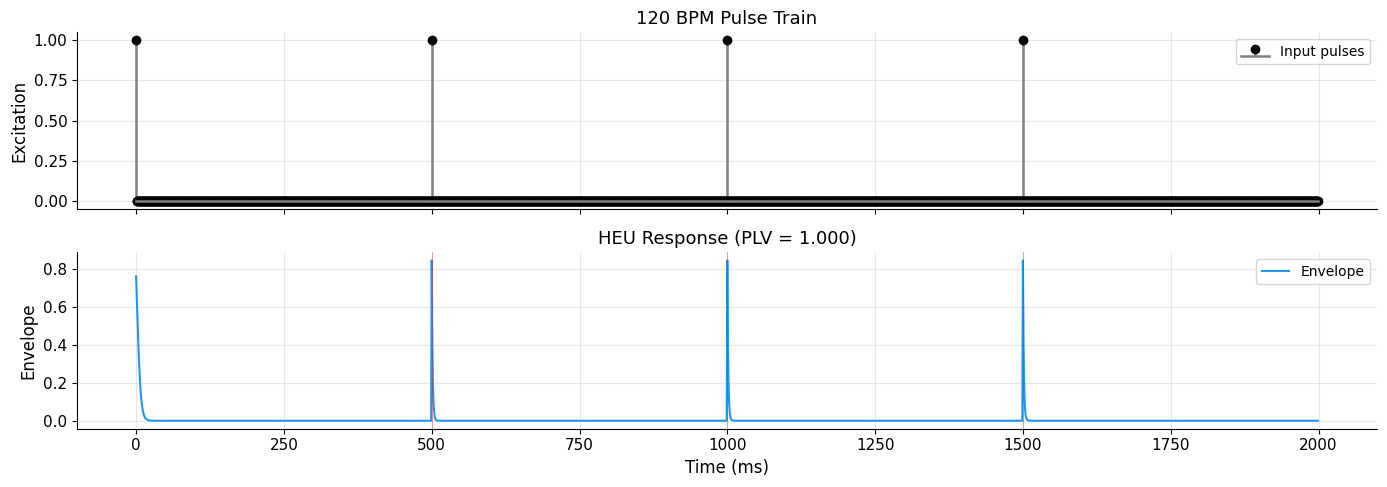


Expected beat period: 500 ms
Measured mean ISI: 500.0 ms
ISI range: [500, 500] ms


In [3]:
# Visualize first 2 seconds at 120 BPM
bpm = 120
r = results[bpm]
window = 2000  # 2 seconds

fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)

# Input pulses
axes[0].stem(
    r["time_ms"][:window],
    r["signal"][:window],
    linefmt="gray",
    markerfmt="ko",
    basefmt="gray",
    label="Input pulses",
)
axes[0].set_ylabel("Excitation")
axes[0].set_title(f"{bpm} BPM Pulse Train")
axes[0].legend()

# Envelope response
axes[1].plot(
    r["time_ms"][:window], r["envelope"][:window], color="#2196F3", linewidth=1.5, label="Envelope"
)
for st in r["spike_times"]:
    if st < window:
        axes[1].axvline(st, color="red", alpha=0.3, linewidth=0.8)
axes[1].set_ylabel("Envelope")
axes[1].set_xlabel("Time (ms)")
axes[1].set_title(f"HEU Response (PLV = {r['plv']:.3f})")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nExpected beat period: {60000 / bpm:.0f} ms")
print(f"Measured mean ISI: {r['isi']['mean_isi_ms']:.1f} ms")
print(f"ISI range: [{r['isi']['min_isi_ms']:.0f}, {r['isi']['max_isi_ms']:.0f}] ms")

## 2. Phase Locking Visualization

The Phase Locking Value (PLV) measures how consistently spikes occur at the same phase relative to the driving pulse. PLV = 1.0 means perfect locking.

We visualize this with a **polar plot** where each spike is plotted at its phase angle. Clustered points = strong locking.

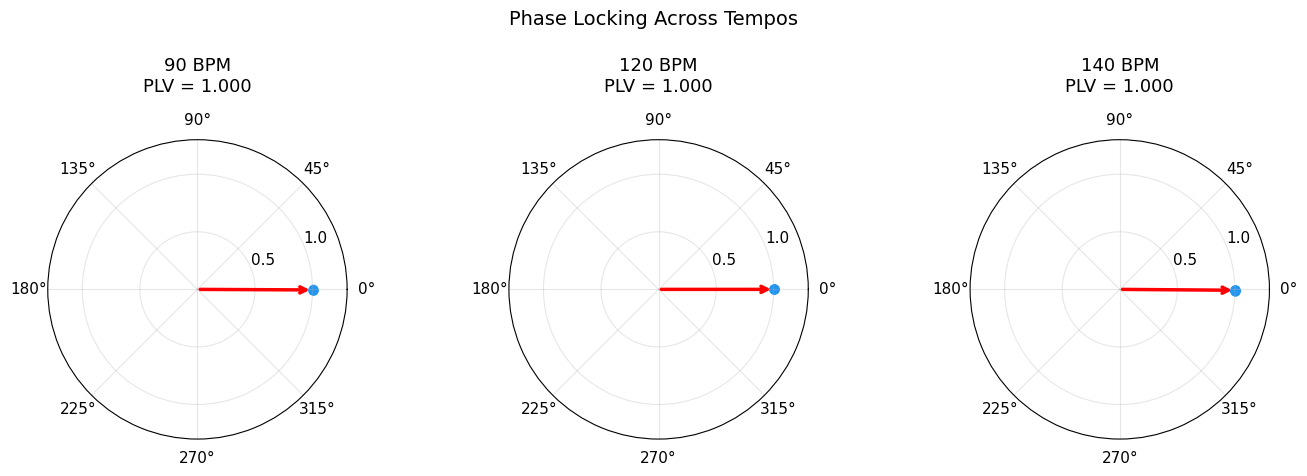

All points cluster at the same angle = perfect phase locking.
The red arrow shows the mean phase vector (length = PLV).


In [4]:
# Phase polar plots for each tempo
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), subplot_kw={"projection": "polar"})

for idx, bpm in enumerate(tempos):
    r = results[bpm]
    beat_period_ms = 60000.0 / bpm

    # Compute phases
    phases = (r["spike_times"] % beat_period_ms) / beat_period_ms * 2 * np.pi

    # Plot spikes
    axes[idx].scatter(phases, np.ones_like(phases), alpha=0.5, s=40, color="#2196F3")

    # Mean vector
    mean_phase = np.angle(np.mean(np.exp(1j * phases)))
    plv = abs(np.mean(np.exp(1j * phases)))
    axes[idx].annotate(
        "",
        xy=(mean_phase, plv),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color="red", lw=2.5),
    )

    axes[idx].set_ylim(0, 1.3)
    axes[idx].set_title(f"{bpm} BPM\nPLV = {r['plv']:.3f}", pad=15)
    axes[idx].set_rticks([0.5, 1.0])

fig.suptitle("Phase Locking Across Tempos", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("All points cluster at the same angle = perfect phase locking.")
print("The red arrow shows the mean phase vector (length = PLV).")

## 3. Accent Sensitivity (Natural Compression)

Real musicians don't respond linearly to dynamics - a 50% louder note doesn't produce 50% higher peak. The HEU exhibits similar **natural compression**.

With `attack_bias=0.5`, a 1.5x input strength produces ~1.19x output peak.

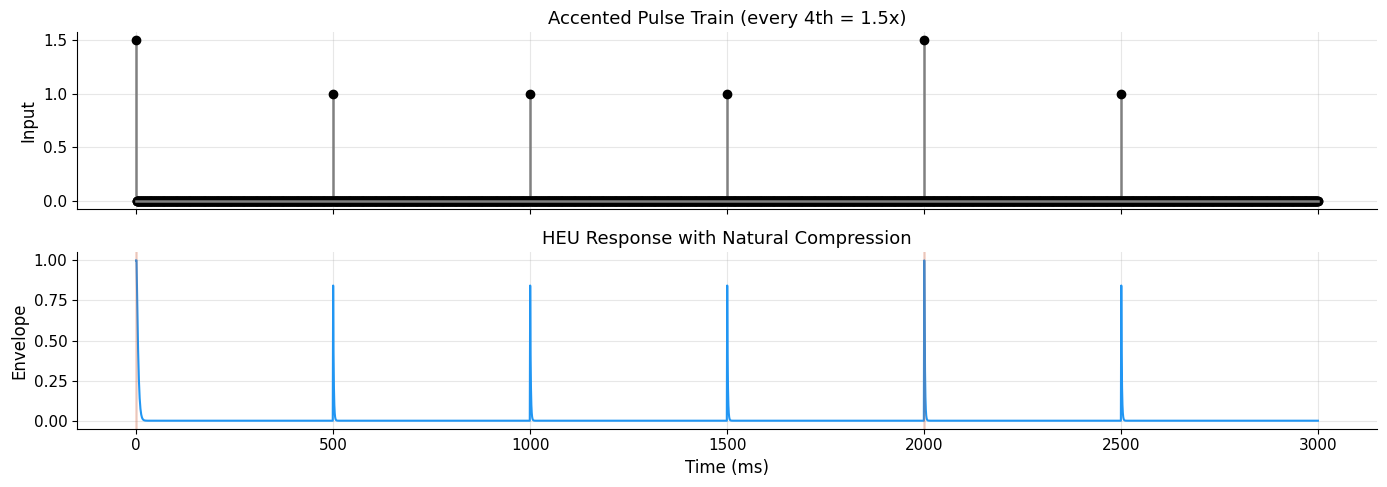

Input accent ratio: 1.50x
Output accent ratio: 1.19x
Mean accent peak: 1.000
Mean non-accent peak: 0.843

Compression: 1.5x input -> 1.19x output
This is similar to how real instruments compress dynamics naturally.


In [5]:
# Accent test: every 4th beat is 1.5x amplitude
bpm = 120
duration_sec = 5.0
accent_strength = 1.5

unit = HHEnvelopeUnit()
time_ms, signal = accented_pulse_train(
    bpm, duration_sec, accent_every=4, accent_strength=accent_strength
)
pulse_times = get_pulse_times(bpm, duration_sec)
envelope, spike_times = run_heu_simulation(unit, signal)

# Measure accent vs non-accent peaks
beat_period_ms = 60000.0 / bpm
window_samples = int(min(0.1 * beat_period_ms, 60.0))

accent_peaks = []
non_accent_peaks = []

for i, pt in enumerate(pulse_times):
    idx = int(pt)
    end = min(idx + window_samples, len(envelope))
    if idx < len(envelope) and end > idx:
        peak = float(np.max(envelope[idx:end]))
        if i % 4 == 0:
            accent_peaks.append(peak)
        else:
            non_accent_peaks.append(peak)

mean_accent = np.mean(accent_peaks)
mean_non_accent = np.mean(non_accent_peaks)
accent_ratio = mean_accent / mean_non_accent if mean_non_accent > 0 else 0

# Plot first 3 seconds
window = 3000
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)

axes[0].stem(time_ms[:window], signal[:window], linefmt="gray", markerfmt="ko", basefmt="gray")
axes[0].set_ylabel("Input")
axes[0].set_title(f"Accented Pulse Train (every 4th = {accent_strength}x)")

axes[1].plot(time_ms[:window], envelope[:window], color="#2196F3", linewidth=1.5)
# Mark accent beats
for i, pt in enumerate(pulse_times):
    if pt < window and i % 4 == 0:
        axes[1].axvline(pt, color="#E64A19", alpha=0.2, linewidth=2)
axes[1].set_ylabel("Envelope")
axes[1].set_xlabel("Time (ms)")
axes[1].set_title("HEU Response with Natural Compression")

plt.tight_layout()
plt.show()

print(f"Input accent ratio: {accent_strength:.2f}x")
print(f"Output accent ratio: {accent_ratio:.2f}x")
print(f"Mean accent peak: {mean_accent:.3f}")
print(f"Mean non-accent peak: {mean_non_accent:.3f}")
print(f"\nCompression: {accent_strength}x input -> {accent_ratio:.2f}x output")
print("This is similar to how real instruments compress dynamics naturally.")

## 4. Robustness to Timing Jitter

Real musical performances have timing variations. The HEU should maintain phase locking even with humanized timing.

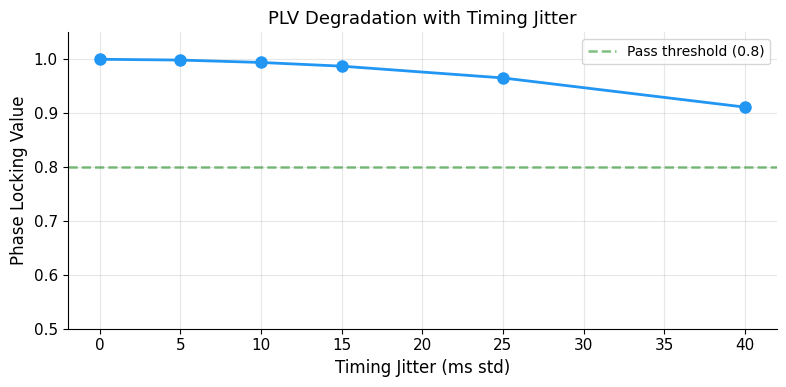


Jitter (ms)     PLV      Status    
-----------------------------------
0               1.000    PASS      
5               0.999    PASS      
10              0.994    PASS      
15              0.987    PASS      
25              0.965    PASS      
40              0.911    PASS      

Typical human jitter: 10-20ms. HEU maintains PLV > 0.95 in this range.


In [12]:
# Test with increasing jitter
bpm = 120
duration_sec = 10.0
jitter_levels = [0, 5, 10, 15, 25, 40]

jitter_results = []

for jitter in jitter_levels:
    unit = HHEnvelopeUnit()
    if jitter == 0:
        time_ms, signal = pulse_train(bpm, duration_sec)
    else:
        time_ms, signal = jittered_pulse_train(bpm, duration_sec, jitter_ms=jitter, seed=42)
    pulse_times = get_pulse_times(bpm, duration_sec)
    envelope, spike_times = run_heu_simulation(unit, signal)

    beat_period_ms = 60000.0 / bpm
    plv = phase_locking_value(pulse_times, spike_times, beat_period_ms)
    jitter_results.append({"jitter_ms": jitter, "plv": plv, "n_spikes": len(spike_times)})

# Plot PLV vs jitter
fig, ax = plt.subplots(figsize=(8, 4))

jitters = [r["jitter_ms"] for r in jitter_results]
plvs = [r["plv"] for r in jitter_results]

ax.plot(jitters, plvs, "o-", color="#2196F3", linewidth=2, markersize=8)
ax.axhline(0.8, color="green", linestyle="--", alpha=0.5, label="Pass threshold (0.8)")
ax.set_xlabel("Timing Jitter (ms std)")
ax.set_ylabel("Phase Locking Value")
ax.set_title("PLV Degradation with Timing Jitter")
ax.set_ylim([0.5, 1.05])
ax.legend()

plt.tight_layout()
plt.show()

print(f"\n{'Jitter (ms)':<15} {'PLV':<8} {'Status':<10}")
print("-" * 35)
for r in jitter_results:
    status = "PASS" if r["plv"] > 0.8 else "DEGRADED"
    print(f"{r['jitter_ms']:<15} {r['plv']:<8.3f} {status:<10}")

print("\nTypical human jitter: 10-20ms. HEU maintains PLV > 0.95 in this range.")

## 5. Inter-Spike Interval Analysis

The ISI histogram shows the distribution of time between consecutive spikes. For perfect locking, all ISIs should equal the beat period.

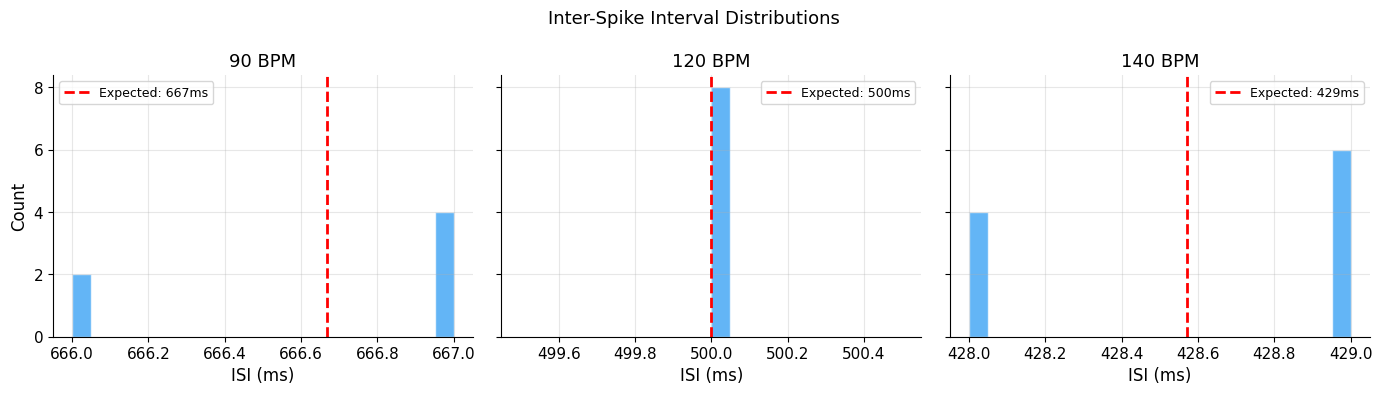

Tight ISI distributions centered on beat period = stable tempo locking.


In [7]:
# ISI histograms for each tempo
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for idx, bpm in enumerate(tempos):
    r = results[bpm]
    beat_period = 60000.0 / bpm

    if len(r["spike_times"]) > 1:
        isis = np.diff(r["spike_times"])
        axes[idx].hist(isis, bins=20, color="#2196F3", alpha=0.7, edgecolor="white")
        axes[idx].axvline(
            beat_period,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Expected: {beat_period:.0f}ms",
        )
        axes[idx].set_title(f"{bpm} BPM")
        axes[idx].set_xlabel("ISI (ms)")
        axes[idx].legend(fontsize=9)

axes[0].set_ylabel("Count")
fig.suptitle("Inter-Spike Interval Distributions", fontsize=13)
plt.tight_layout()
plt.show()

print("Tight ISI distributions centered on beat period = stable tempo locking.")

## 6. Internal Gate Dynamics During Locking

Let's look at what happens inside the HEU during tempo-locked operation.

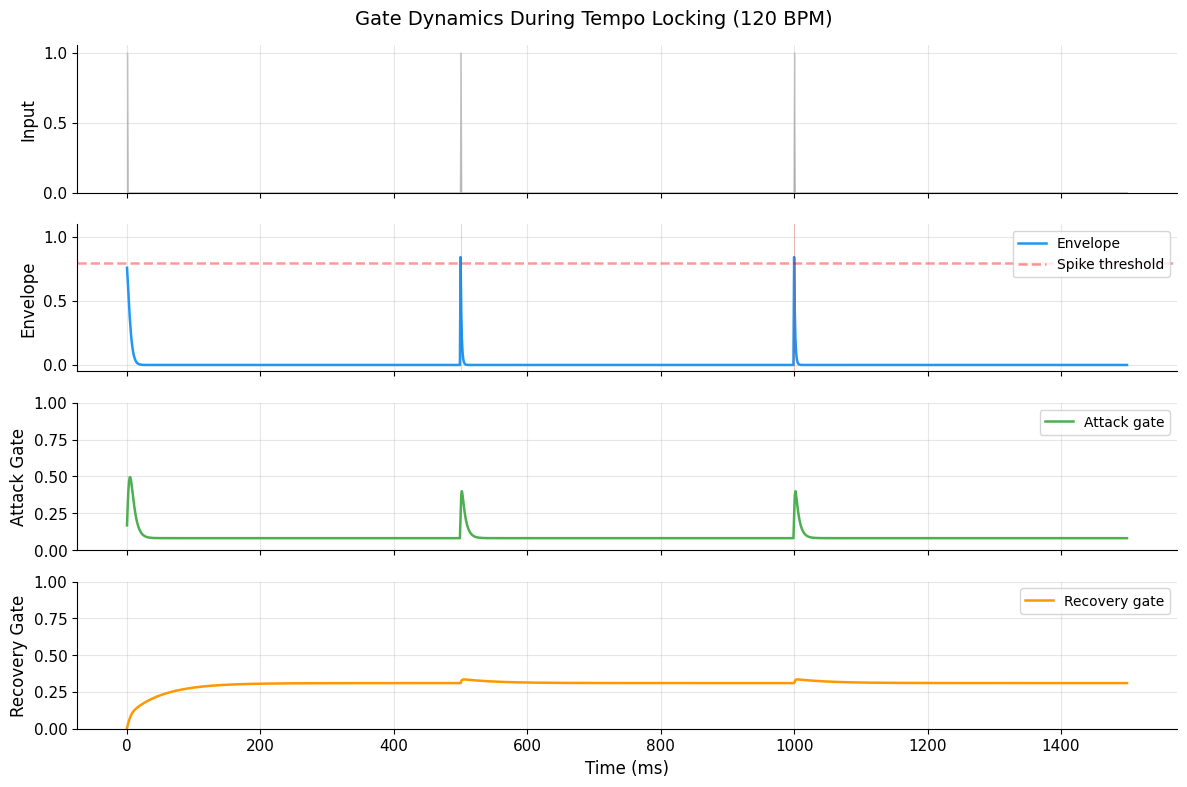

Notice the repeating pattern:
  1. Input pulse arrives
  2. Attack gate spikes (fast positive feedback)
  3. Envelope rises sharply
  4. Recovery gate rises (delayed negative feedback)
  5. Envelope decays back to baseline
  6. Both gates return to resting state before next pulse


In [8]:
# Show gate dynamics for a few beats at 120 BPM
unit = HHEnvelopeUnit()
time_ms, signal = pulse_train(120, 2.0)  # 2 seconds
result = run_heu_with_gates(unit, signal)

# Show first 1.5 seconds (3 beats)
window = 1500

fig = plot_gate_dynamics(
    voltage=result.envelope[:window],
    attack_gate=result.attack_gate[:window],
    recovery_gate=result.recovery_gate[:window],
    time_ms=result.time_ms[:window],
    input_signal=result.input_signal[:window],
    spike_times=result.spike_times[result.spike_times < window],
    title="Gate Dynamics During Tempo Locking (120 BPM)",
)
plt.show()

print("Notice the repeating pattern:")
print("  1. Input pulse arrives")
print("  2. Attack gate spikes (fast positive feedback)")
print("  3. Envelope rises sharply")
print("  4. Recovery gate rises (delayed negative feedback)")
print("  5. Envelope decays back to baseline")
print("  6. Both gates return to resting state before next pulse")

## 7. Summary & Pass Conditions

Let's compile the final results:

In [9]:
print("=" * 60)
print("EXPERIMENT 01: TEMPO LOCKING - RESULTS")
print("=" * 60)

# PLV pass condition
print("\n--- Phase Locking Value (target: > 0.8) ---")
all_pass = True
for bpm, r in results.items():
    status = "PASS" if r["plv"] > 0.8 else "FAIL"
    if r["plv"] <= 0.8:
        all_pass = False
    print(f"  {bpm} BPM: PLV = {r['plv']:.3f} [{status}]")

# Refractory condition
print("\n--- Refractory Enforcement (target: min ISI >= 20ms) ---")
for bpm, r in results.items():
    min_isi = r["isi"]["min_isi_ms"]
    status = "PASS" if min_isi >= 19.5 else "FAIL"
    if min_isi < 19.5:
        all_pass = False
    print(f"  {bpm} BPM: min ISI = {min_isi:.1f} ms [{status}]")

# Accent condition
print("\n--- Accent Sensitivity (target: 1.1-1.4x for 1.5x input) ---")
accent_status = "PASS" if 1.05 <= accent_ratio <= 1.5 else "FAIL"
if not (1.05 <= accent_ratio <= 1.5):
    all_pass = False
print(f"  Accent ratio: {accent_ratio:.2f}x [{accent_status}]")

# Jitter condition
jitter_15_plv = next(r["plv"] for r in jitter_results if r["jitter_ms"] == 15)
print("\n--- Jitter Robustness (target: PLV > 0.8 at 15ms jitter) ---")
jitter_status = "PASS" if jitter_15_plv > 0.8 else "FAIL"
if jitter_15_plv <= 0.8:
    all_pass = False
print(f"  PLV at 15ms jitter: {jitter_15_plv:.3f} [{jitter_status}]")

print("\n" + "=" * 60)
overall = "ALL PASS" if all_pass else "SOME FAIL"
print(f"OVERALL: {overall}")
print("=" * 60)

EXPERIMENT 01: TEMPO LOCKING - RESULTS

--- Phase Locking Value (target: > 0.8) ---
  90 BPM: PLV = 1.000 [PASS]
  120 BPM: PLV = 1.000 [PASS]
  140 BPM: PLV = 1.000 [PASS]

--- Refractory Enforcement (target: min ISI >= 20ms) ---
  90 BPM: min ISI = 666.0 ms [PASS]
  120 BPM: min ISI = 500.0 ms [PASS]
  140 BPM: min ISI = 428.0 ms [PASS]

--- Accent Sensitivity (target: 1.1-1.4x for 1.5x input) ---
  Accent ratio: 1.19x [PASS]

--- Jitter Robustness (target: PLV > 0.8 at 15ms jitter) ---
  PLV at 15ms jitter: 0.987 [PASS]

OVERALL: ALL PASS


---

## Exercises

### Exercise 1: Tempo Extremes

What happens at very slow (40 BPM) or very fast (300 BPM) tempos? At what tempo does locking break down?

In [10]:
# Exercise 1: Test extreme tempos
# Hint: At very fast tempos, refractory period may prevent
# responding to every beat

extreme_tempos = [40, 60, 120, 200, 300, 500]

print(f"{'BPM':<8} {'Beat Period (ms)':<18} {'PLV':<8} {'Spikes/sec':<12} {'Notes':<20}")
print("-" * 70)

for bpm in extreme_tempos:
    unit = HHEnvelopeUnit()
    time_ms, signal = pulse_train(bpm, 5.0)
    pulse_times = get_pulse_times(bpm, 5.0)
    envelope, spike_times = run_heu_simulation(unit, signal)

    beat_period = 60000.0 / bpm
    plv = phase_locking_value(pulse_times, spike_times, beat_period)
    spikes_per_sec = len(spike_times) / 5.0

    notes = ""
    if beat_period < 20:
        notes = "Below refractory!"
    elif plv < 0.8:
        notes = "Locking degraded"

    print(f"{bpm:<8} {beat_period:<18.1f} {plv:<8.3f} {spikes_per_sec:<12.1f} {notes:<20}")

BPM      Beat Period (ms)   PLV      Spikes/sec   Notes               
----------------------------------------------------------------------
40       1500.0             1.000    0.6                              
60       1000.0             1.000    0.8                              
120      500.0              1.000    1.8                              
200      300.0              1.000    3.2                              
300      200.0              1.000    4.8                              
500      120.0              1.000    8.2                              


### Exercise 2: Syncopation

What happens when every other beat is removed (half-time feel)? Does the HEU maintain locking at the new effective tempo?

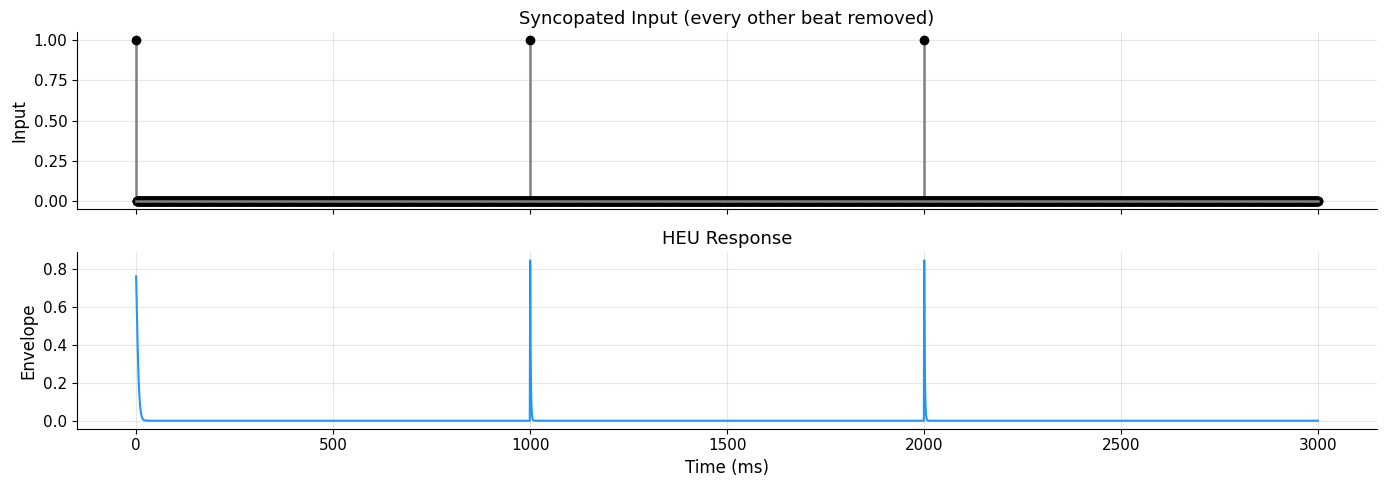

Mean ISI: 1000.0 ms (expected: 1000 ms for half-time)


In [11]:
# Exercise 2: Create a syncopated pattern
bpm = 120
duration_sec = 5.0

# Regular pulse train, then remove every other pulse
time_ms, signal = pulse_train(bpm, duration_sec)
pulse_times = get_pulse_times(bpm, duration_sec)

# Keep only odd-numbered beats (syncopated)
syncopated_signal = signal.copy()
beat_period_ms = 60000.0 / bpm
for i, pt in enumerate(pulse_times):
    if i % 2 == 1:  # Remove even beats
        idx = int(pt)
        if idx < len(syncopated_signal):
            syncopated_signal[idx] = 0.0

unit = HHEnvelopeUnit()
envelope, spike_times = run_heu_simulation(unit, syncopated_signal)

# Plot
window = 3000
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axes[0].stem(
    time_ms[:window], syncopated_signal[:window], linefmt="gray", markerfmt="ko", basefmt="gray"
)
axes[0].set_title("Syncopated Input (every other beat removed)")
axes[0].set_ylabel("Input")

axes[1].plot(time_ms[:window], envelope[:window], color="#2196F3", linewidth=1.5)
axes[1].set_title("HEU Response")
axes[1].set_ylabel("Envelope")
axes[1].set_xlabel("Time (ms)")

plt.tight_layout()
plt.show()

if len(spike_times) > 1:
    isis = np.diff(spike_times)
    print(f"Mean ISI: {np.mean(isis):.1f} ms (expected: {beat_period_ms * 2:.0f} ms for half-time)")

---

## Next: [Notebook 02 - Two-Voice Coupling](./02_two_voice_coupling_exp02.ipynb)